# Classification de fleurs par transfer learning (ResNet50)

**Auteure :** Ndeye Maimouna Badiane — étudiante ingénieure en Mathématiques Appliquées et Modélisation, Polytech Lyon
**Cadre :** projet personnel, 2026
**Outils :** Python, TensorFlow / Keras, TensorFlow Datasets, Scikit-learn, Matplotlib, Google Colab (GPU T4)

---

## Objectif

Reconnaître automatiquement le **type de fleur** sur une photo, parmi **5 catégories** : pissenlit, marguerite, tulipe, tournesol et rose.

C'est un problème de **classification d'images multi-classes**, en apprentissage supervisé, traité par **deep learning**.

## La difficulté

Le jeu de données `tf_flowers` ne contient que **3 670 photos**. C'est trop peu pour entraîner de zéro un réseau profond de plusieurs millions de paramètres : il apprendrait les images par cœur au lieu de généraliser.

## La méthode : le transfer learning

On réutilise **ResNet50**, un réseau convolutif de 50 couches déjà entraîné sur plus d'un million d'images d'**ImageNet**. Il sait déjà reconnaître des formes, des textures et des couleurs. Le travail se fait en deux phases :

1. **ResNet50 gelé** : on garde ses poids tels quels et on n'entraîne qu'une nouvelle tête de classification à 5 sorties.
2. **Fine-tuning** : on dégèle les dernières couches de ResNet50 et on les ajuste doucement, avec un learning rate très faible.

## Résultat principal

**93,8 % de bonnes réponses sur le jeu de test** (516 photos sur 550), un jeu jamais utilisé avant l'évaluation finale.

## Plan du notebook

0. Réglages et chargement des bibliothèques
1. Chargement et découpage des données
2. Exploration des données
3. Préparation des images pour ResNet50
4. Construction du modèle (ResNet50 gelé + nouvelle tête)
5. Entraînement de la tête
6. Fine-tuning
7. Évaluation finale sur le jeu de test
8. Analyse des erreurs
9. Conclusion

> Pour exécuter ce notebook dans Colab, activer la carte graphique : *Exécution → Modifier le type d'exécution → GPU T4*.

## 0. Réglages et bibliothèques

**Objectif :** charger les outils et fixer le hasard pour que les résultats soient reproductibles.

- `tensorflow` : la bibliothèque de deep learning (Keras est inclus dedans).
- `tensorflow_datasets` : un catalogue de jeux de données publics, dont `tf_flowers`.
- `matplotlib` : pour les graphiques et l'affichage des images.
- `set_random_seed(42)` fixe le hasard (mélange des images, initialisation des poids, augmentation). Sur GPU, de petites variations peuvent subsister d'une exécution à l'autre.

In [4]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

tf.keras.utils.set_random_seed(42)

# Vérifier que la carte graphique est bien active
print("GPU disponible :", tf.config.list_physical_devices("GPU"))

GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Chargement et découpage des données

**Objectif :** charger les photos et mettre de côté, dès le départ, des photos que le modèle ne verra jamais pendant l'apprentissage.

`tf_flowers` n'est livré qu'avec un seul bloc nommé `"train"`, qui contient les 3 670 photos. On le coupe en trois tranches :

| Groupe | Part | Rôle |
| --- | --- | --- |
| Entraînement | 70 % | Le modèle apprend dessus |
| Validation | 15 % | On surveille l'apprentissage et on fait nos choix |
| Test | 15 % | L'examen final, utilisé une seule fois |

- `as_supervised=True` : chaque élément est une paire **(photo, étiquette)**, l'étiquette étant un numéro de 0 à 4.
- `with_info=True` : on récupère aussi la description du jeu, dont les noms des classes.

On utilise une validation fixe plutôt qu'une validation croisée : chaque entraînement est long, et on veut surveiller le modèle à chaque époque.

In [5]:
(train_ds, val_ds, test_ds), info = tfds.load(
    "tf_flowers",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True,
    with_info=True,
)

noms_classes = info.features["label"].names
print("Classes :", noms_classes)
print("Nombre total de photos :", info.splits["train"].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.HBRPOI_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Classes : ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Nombre total de photos : 3670


## 2. Exploration des données

**Objectif :** vérifier que les 5 fleurs sont représentées de façon à peu près équilibrée dans chaque groupe, et regarder à quoi ressemblent les photos.

La fonction `compter` parcourt un groupe, récupère l'étiquette de chaque photo et renvoie un **dictionnaire** `{nom de la fleur : nombre de photos}`.

In [6]:
def compter(ds):
    etiquettes = [int(label) for _, label in ds]
    comptes = Counter(etiquettes)
    return {noms_classes[i]: comptes[i] for i in range(len(noms_classes))}

print("Entraînement :", compter(train_ds))
print("Validation   :", compter(val_ds))
print("Test         :", compter(test_ds))

Entraînement : {'dandelion': 639, 'daisy': 445, 'tulips': 531, 'sunflowers': 496, 'roses': 458}
Validation   : {'dandelion': 147, 'daisy': 93, 'tulips': 134, 'sunflowers': 101, 'roses': 76}
Test         : {'dandelion': 112, 'daisy': 95, 'tulips': 134, 'sunflowers': 102, 'roses': 107}


**Résultats obtenus :**

| Fleur | Entraînement | Validation | Test |
| --- | --- | --- | --- |
| Pissenlit (*dandelion*) | 639 | 147 | 112 |
| Marguerite (*daisy*) | 445 | 93 | 95 |
| Tulipe (*tulips*) | 531 | 134 | 134 |
| Tournesol (*sunflowers*) | 496 | 101 | 102 |
| Rose (*roses*) | 458 | 76 | 107 |
| **Total** | **2 569** | **551** | **550** |

Les classes sont **à peu près équilibrées** : aucune fleur n'est très rare. L'accuracy est donc un indicateur global pertinent, que l'on complétera par la précision et le rappel par classe.

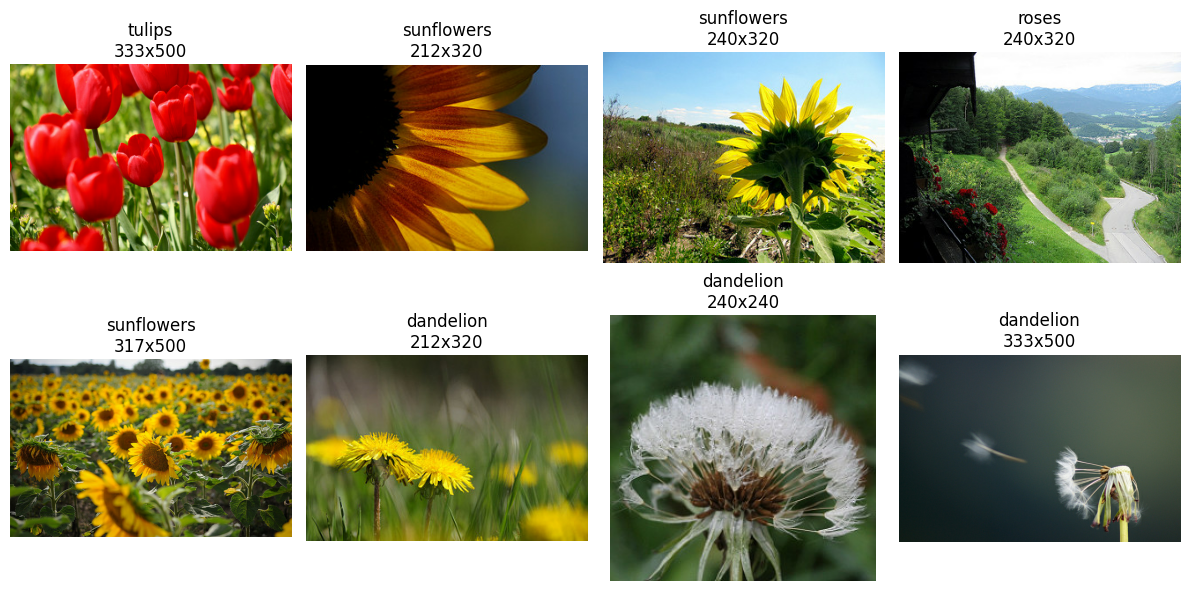

In [7]:
plt.figure(figsize=(12, 6))
for i, (image, label) in enumerate(train_ds.take(8)):
    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(f"{noms_classes[label]}\n{image.shape[0]}x{image.shape[1]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

**Observation :** les photos sont en couleur et de **tailles différentes**. Or ResNet50 attend des images de taille fixe : il faut donc les préparer.

## 3. Préparation des images pour ResNet50

**Objectif :** mettre chaque photo exactement au format que ResNet50 a connu pendant son entraînement sur ImageNet.

La fonction `preparer` fait deux choses :
1. `tf.image.resize` : redimensionne la photo en **224 × 224 pixels**, la taille d'entrée de ResNet50.
2. `preprocess_input` : applique la préparation propre à ResNet50 (passage des canaux en BGR et soustraction de la couleur moyenne d'ImageNet). Il ne s'agit **pas** d'une simple mise à l'échelle entre 0 et 1.

Ensuite, on construit un **pipeline** de données avec `tf.data` :
- `shuffle(1000)` : mélange les photos d'entraînement à chaque époque (pas la validation ni le test, inutile).
- `map(preparer)` : applique la préparation à chaque photo.
- `batch(32)` : regroupe les photos par lots de 32.
- `prefetch` : prépare le lot suivant pendant que le GPU traite le lot courant.

In [8]:
from tensorflow.keras.applications.resnet50 import preprocess_input

TAILLE = (224, 224)
LOT = 32

def preparer(image, label):
    image = tf.image.resize(image, TAILLE)
    image = preprocess_input(image)
    return image, label

train_prep = train_ds.shuffle(1000).map(preparer).batch(LOT).prefetch(tf.data.AUTOTUNE)
val_prep   = val_ds.map(preparer).batch(LOT).prefetch(tf.data.AUTOTUNE)
test_prep  = test_ds.map(preparer).batch(LOT).prefetch(tf.data.AUTOTUNE)

images, labels = next(iter(train_prep))
print("Forme d'un lot :", images.shape)
print("Valeurs min / max :", float(tf.reduce_min(images)), float(tf.reduce_max(images)))

Forme d'un lot : (32, 224, 224, 3)
Valeurs min / max : -123.68000030517578 151.06100463867188


## 4. Construction du modèle : ResNet50 gelé + nouvelle tête

**Objectif :** réutiliser ce que ResNet50 sait déjà et n'ajouter qu'une petite partie propre à nos 5 fleurs.

**La base (backbone) :**
- `weights="imagenet"` : on charge les poids appris sur ImageNet.
- `include_top=False` : on retire la dernière couche d'origine, qui classait 1 000 catégories d'ImageNet.
- `base.trainable = False` : on **gèle** la base, ses poids ne bougeront pas pendant cette phase.

**L'augmentation de données** (seulement pendant l'entraînement) crée à chaque époque des variantes aléatoires des photos : retournement horizontal, petite rotation, petit zoom. Le modèle voit ainsi plus de diversité et apprend moins par cœur.

**La nouvelle tête de classification :**
- `GlobalAveragePooling2D` : résume chaque photo en un vecteur de **2 048 caractéristiques** (la moyenne de chacune des 2 048 cartes produites par ResNet50).
- `Dropout(0.2)` : éteint au hasard 20 % de ces valeurs pendant l'entraînement, contre le surapprentissage.
- `Dense(5, activation="softmax")` : 5 sorties, une par fleur, transformées en probabilités qui somment à 1.

`base(x, training=False)` garde les couches de normalisation de ResNet50 en mode « utilisation », ce qui est important pour le fine-tuning plus tard.

In [9]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, Sequential, Model

base = ResNet50(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base.trainable = False

augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

entree = layers.Input(shape=(224, 224, 3))
x = augmentation(entree)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
sortie = layers.Dense(5, activation="softmax")(x)

modele = Model(entree, sortie)
modele.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

**Résultat obtenu :**

| Paramètres | Nombre |
| --- | --- |
| Total | 23 597 957 |
| Entraînables (la tête seule) | **10 245** |

On n'entraîne que **10 245 paramètres** sur près de 24 millions : 2 048 × 5 poids + 5 biais. Avec 2 569 photos, c'est un problème à notre portée.

## 5. Entraînement de la tête

**Objectif :** apprendre à la nouvelle tête à reconnaître les 5 fleurs à partir des caractéristiques de ResNet50.

**Les réglages (`compile`) :**
- `Adam(learning_rate=0.001)` : l'optimiseur. Le learning rate est la taille des pas de correction des poids ; 0,001 convient à une tête qui part de zéro.
- `sparse_categorical_crossentropy` : la fonction de perte pour plusieurs classes, quand l'étiquette est un simple numéro (0 à 4).
- `accuracy` : la part de photos bien classées, pour suivre l'apprentissage.

**L'arrêt anticipé (`EarlyStopping`) :** si la perte de validation ne s'améliore plus pendant 3 époques (`patience=3`), on arrête et on revient aux meilleurs poids (`restore_best_weights=True`).

Une **époque** est un passage complet sur les 2 569 photos d'entraînement, soit 81 lots de 32.

In [10]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

modele.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

arret = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

historique = modele.fit(
    train_prep,
    validation_data=val_prep,
    epochs=15,
    callbacks=[arret],
)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 34s 218ms/step - accuracy: 0.7236 - loss: 0.7632 - val_accuracy: 0.8530 - val_loss: 0.4249
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 30s 155ms/step - accuracy: 0.8704 - loss: 0.3714 - val_accuracy: 0.8893 - val_loss: 0.3180
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 21s 155ms/step - accuracy: 0.8879 - loss: 0.3059 - val_accuracy: 0.9038 - val_loss: 0.2954
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 156ms/step - accuracy: 0.9109 - loss: 0.2630 - val_accuracy: 0.9111 - val_loss: 0.2861
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 169ms/step - accuracy: 0.9093 - loss: 0.2460 - val_accuracy: 0.9111 - val_loss: 0.2866
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 20s 158ms/step - accuracy: 0.9175 - loss: 0.2243 - val_accuracy: 0.9129 - val_loss: 0.2807
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 159ms/step - accuracy: 0.9295 - loss: 0.1945 - val_accuracy: 0.9129 - val_loss: 0.2672
Epoch 8/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 160ms/step - accuracy: 0.9303 - loss: 0.1915 - val_accu

### Courbes d'apprentissage

**Objectif :** vérifier que le modèle apprend et repérer un éventuel surapprentissage, c'est-à-dire un écart qui se creuse entre l'entraînement et la validation.

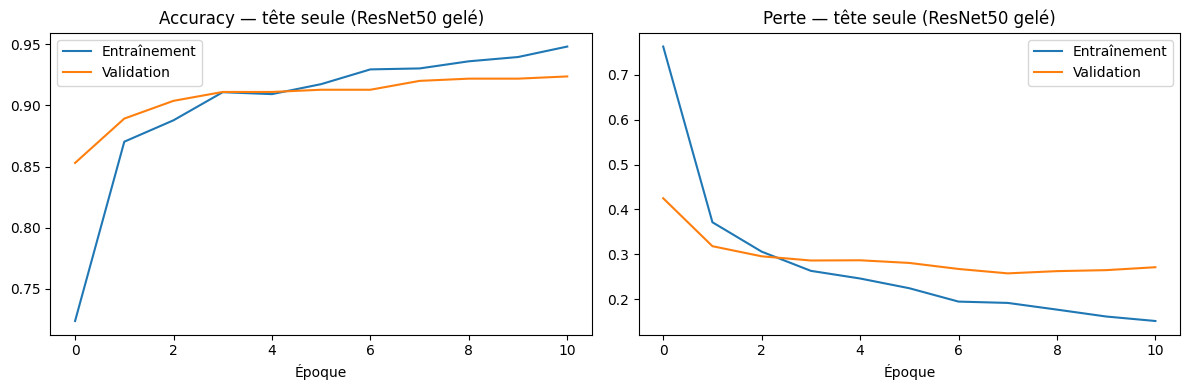

In [11]:
def tracer(hist, titre):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(hist["accuracy"], label="Entraînement")
    plt.plot(hist["val_accuracy"], label="Validation")
    plt.title(f"Accuracy — {titre}")
    plt.xlabel("Époque"); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(hist["loss"], label="Entraînement")
    plt.plot(hist["val_loss"], label="Validation")
    plt.title(f"Perte — {titre}")
    plt.xlabel("Époque"); plt.legend()
    plt.tight_layout()
    plt.show()

tracer(historique.history, "tête seule (ResNet50 gelé)")

**Résultat obtenu :** environ **92 % d'accuracy en validation** avec la tête seule, et l'arrêt anticipé a stoppé l'entraînement après une dizaine d'époques.

Les courbes d'entraînement et de validation restent proches : pas de surapprentissage marqué. La validation est même parfois au-dessus de l'entraînement, ce qui est normal ici, car l'augmentation et le dropout ne s'appliquent que pendant l'entraînement et rendent cette tâche plus difficile.

## 6. Fine-tuning

**Objectif :** gagner encore quelques points en adaptant légèrement ResNet50 lui-même à nos fleurs.

**Le principe :**
- Les premières couches de ResNet50 détectent des motifs **généraux** (bords, couleurs, textures), utiles pour n'importe quelle image : on les laisse gelées.
- Les dernières couches détectent des motifs plus **spécifiques** : ce sont elles qu'on dégèle, ici les **30 dernières couches**.

**Pourquoi un learning rate 100 fois plus petit (1e-5) ?** Les couches dégelées sont déjà très bonnes. De grands pas risqueraient d'effacer ce qu'elles ont appris sur ImageNet ; de tout petits pas les ajustent délicatement.

**Pourquoi seulement après la phase 1 ?** Au départ, la tête est aléatoire et ses erreurs sont grandes : dégeler tout de suite aurait abîmé les poids pré-entraînés. On stabilise d'abord la tête, puis on affine.

Il faut **recompiler** le modèle après avoir changé ce qui est entraînable.

In [12]:
base.trainable = True
for couche in base.layers[:-30]:
    couche.trainable = False

modele.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

nb_entrainables = sum(int(tf.size(p)) for p in modele.trainable_weights)
print("Paramètres entraînables :", f"{nb_entrainables:,}")

historique_ft = modele.fit(
    train_prep,
    validation_data=val_prep,
    epochs=10,
    callbacks=[arret],
)

Paramètres entraînables : 14,460,421
Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 32s 243ms/step - accuracy: 0.8840 - loss: 0.3170 - val_accuracy: 0.9074 - val_loss: 0.2722
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 216ms/step - accuracy: 0.9319 - loss: 0.1886 - val_accuracy: 0.9183 - val_loss: 0.2557
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 213ms/step - accuracy: 0.9521 - loss: 0.1466 - val_accuracy: 0.9274 - val_loss: 0.2342
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 210ms/step - accuracy: 0.9560 - loss: 0.1264 - val_accuracy: 0.9328 - val_loss: 0.2306
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 211ms/step - accuracy: 0.9685 - loss: 0.1071 - val_accuracy: 0.9347 - val_loss: 0.2238
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 210ms/step - accuracy: 0.9708 - loss: 0.0910 - val_accuracy: 0.9347 - val_loss: 0.2181
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 211ms/step - accuracy: 0.9798 - loss: 0.0704 - val_accuracy: 0.9328 - val_loss: 0.2091
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 212ms/step - accur

**Résultat obtenu :** environ **14,5 millions de paramètres entraînables** (14 460 421), contre 10 245 avant. La validation monte vers **94 %**.

### Courbes complètes (phase 1 + fine-tuning)

La ligne verticale marque le début du fine-tuning.

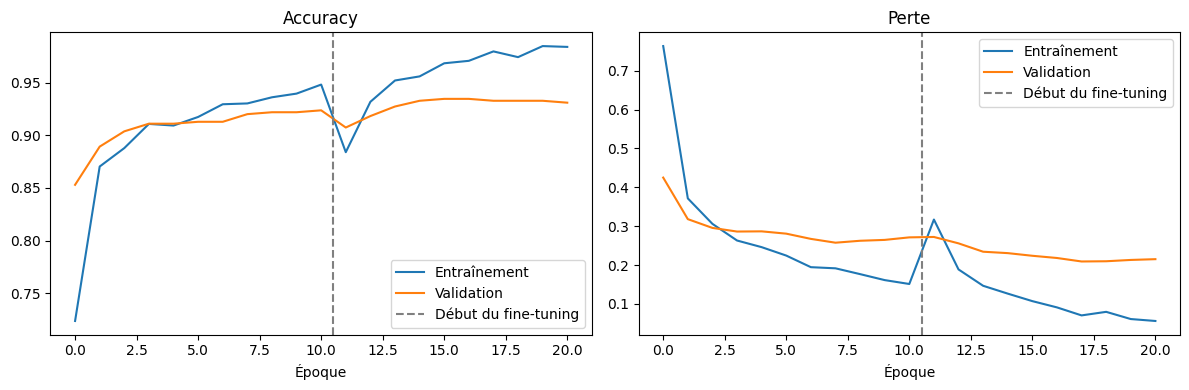

In [13]:
hist_total = {k: historique.history[k] + historique_ft.history[k] for k in historique.history}
debut_ft = len(historique.history["accuracy"])

plt.figure(figsize=(12, 4))
for i, (cle, nom) in enumerate([("accuracy", "Accuracy"), ("loss", "Perte")]):
    plt.subplot(1, 2, i + 1)
    plt.plot(hist_total[cle], label="Entraînement")
    plt.plot(hist_total["val_" + cle], label="Validation")
    plt.axvline(debut_ft - 0.5, color="gray", linestyle="--", label="Début du fine-tuning")
    plt.title(nom); plt.xlabel("Époque"); plt.legend()
plt.tight_layout()
plt.show()

**Lecture :** après la ligne, l'accuracy d'entraînement fait un saut, car le réseau s'adapte enfin aux fleurs, et la validation gagne environ 2 points. L'écart entre les deux courbes reste modéré.

## 7. Évaluation finale sur le jeu de test

**Objectif :** mesurer honnêtement la performance sur **550 photos jamais vues**, ni pour l'entraînement ni pour les réglages. Le test n'est utilisé **qu'une seule fois**, à la fin.

- `evaluate` donne la perte et l'accuracy globales.
- `predict` donne, pour chaque photo, 5 probabilités ; `argmax` garde la fleur la plus probable.
- `classification_report` donne la **précision** (quand le modèle dit « rose », a-t-il raison ?), le **rappel** (parmi les vraies roses, combien sont trouvées ?) et le **F1** (le compromis des deux), pour chaque fleur.

In [14]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

perte_test, acc_test = modele.evaluate(test_prep)
print(f"Accuracy sur le test : {acc_test:.1%}")

probas = modele.predict(test_prep)
y_pred = np.argmax(probas, axis=1)
y_vrai = np.concatenate([labels.numpy() for _, labels in test_prep])

print(classification_report(y_vrai, y_pred, target_names=noms_classes, digits=2))

18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 180ms/step - accuracy: 0.9327 - loss: 0.2134
Accuracy sur le test : 93.3%
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 212ms/step
              precision    recall  f1-score   support

   dandelion       0.96      0.98      0.97       112
       daisy       0.97      0.95      0.96        95
      tulips       0.91      0.93      0.92       134
  sunflowers       0.93      0.92      0.93       102
       roses       0.90      0.88      0.89       107

    accuracy                           0.93       550
   macro avg       0.93      0.93      0.93       550
weighted avg       0.93      0.93      0.93       550



**Résultats obtenus : 93,8 % d'accuracy sur le test (516 / 550).**

| Fleur | Précision | Rappel |
| --- | --- | --- |
| Pissenlit | 0,94 | 0,98 |
| Marguerite | 0,97 | 0,94 |
| Tulipe | 0,92 | 0,94 |
| Tournesol | 0,95 | 0,95 |
| Rose | 0,92 | **0,88** |

Le score de test est **cohérent avec la validation** (environ 94 %) : le modèle généralise bien. Toutes les fleurs dépassent 88 % de rappel ; la **rose** est la plus difficile.

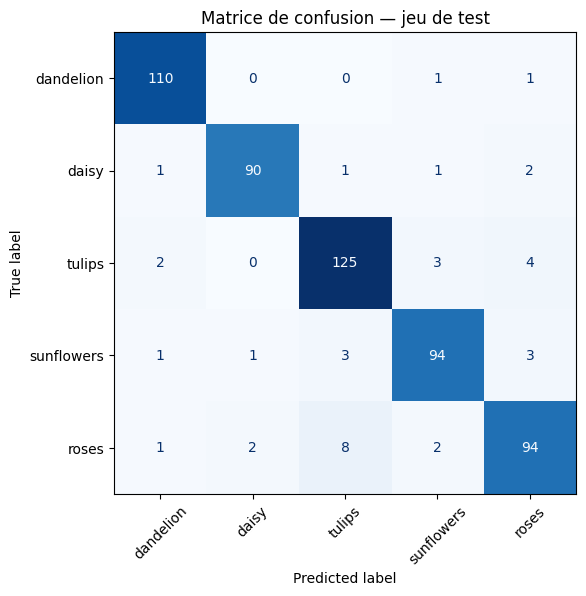

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_vrai, y_pred, display_labels=noms_classes, cmap="Blues", ax=ax, colorbar=False
)
plt.xticks(rotation=45)
plt.title("Matrice de confusion — jeu de test")
plt.show()

**Lecture de la matrice de confusion** (lignes = vraie fleur, colonnes = fleur prédite) :

- La diagonale est très forte : la grande majorité des photos sont bien classées.
- La confusion principale : **9 roses prédites tulipes**. Les deux fleurs ont des couleurs (rouge, rose) et des formes de pétales proches.
- Les autres erreurs sont dispersées, une ou deux par case.

## 8. Analyse des erreurs

**Objectif :** regarder les photos mal classées pour comprendre **pourquoi** le modèle se trompe, au-delà des chiffres.

On récupère les photos de test redimensionnées **sans** `preprocess_input`, pour les afficher avec leurs vraies couleurs. `np.where(y_pred != y_vrai)` donne les positions des erreurs ; on en affiche 10, avec la vraie fleur, la fleur prédite et la confiance du modèle.

Nombre d'erreurs : 37 sur 550


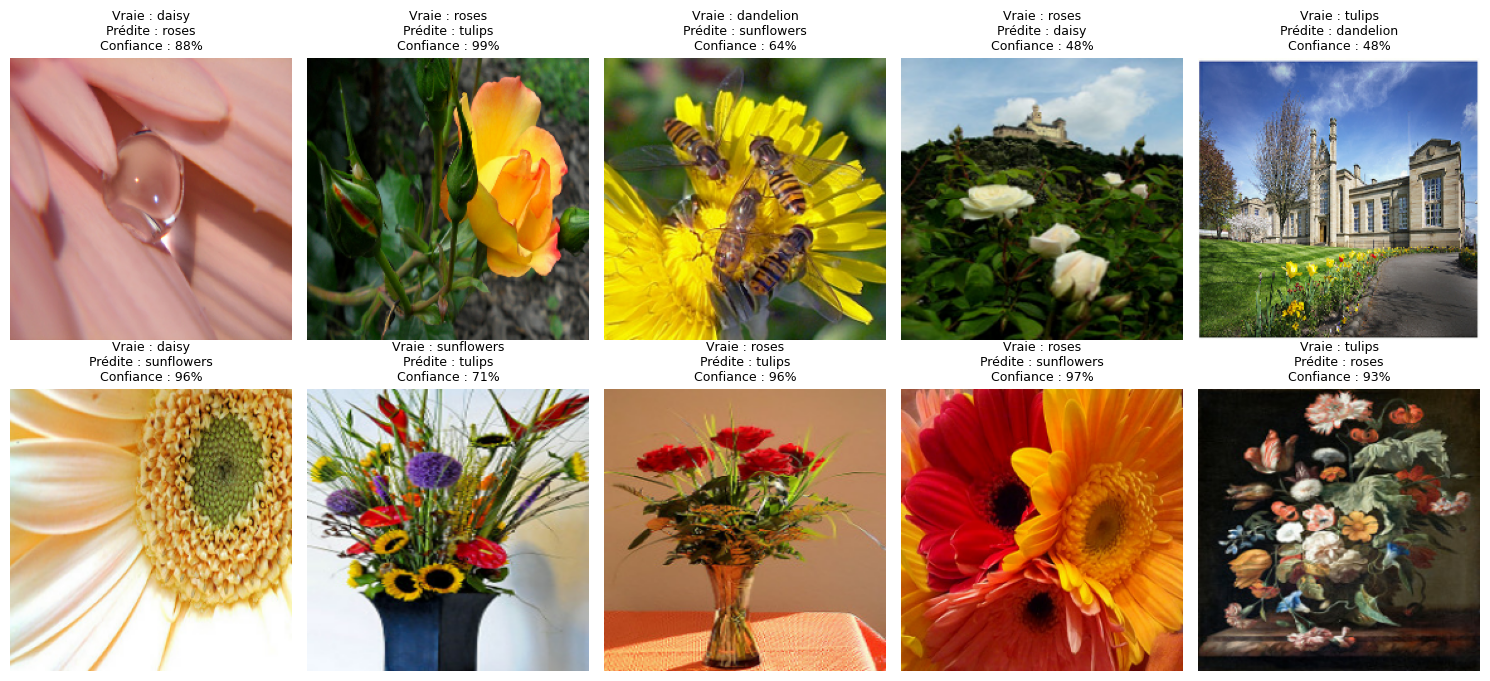

In [16]:
images_test = np.concatenate([
    tf.image.resize(img, TAILLE).numpy()[None] for img, _ in test_ds
]).astype("uint8")

erreurs = np.where(y_pred != y_vrai)[0]
print("Nombre d'erreurs :", len(erreurs), "sur", len(y_vrai))

plt.figure(figsize=(15, 7))
for i, idx in enumerate(erreurs[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images_test[idx])
    plt.title(
        f"Vraie : {noms_classes[y_vrai[idx]]}\n"
        f"Prédite : {noms_classes[y_pred[idx]]}\n"
        f"Confiance : {probas[idx].max():.0%}",
        fontsize=9,
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

**Observations sur les erreurs :**

- **Des étiquettes discutables** : certaines photos étiquetées « rose » montrent en réalité des gerberas. Le modèle n'a pas toujours tort, c'est parfois la donnée.
- **Des photos ambiguës** : un champ de tulipes vu de loin, un gros plan de marguerite, une peinture plutôt qu'une photo.
- **Un modèle parfois trop confiant** : certaines erreurs sont faites avec 95 à 99 % de confiance. Les probabilités du softmax ne sont donc pas toujours fiables comme mesure de certitude.

## 9. Conclusion

| Étape | Accuracy |
| --- | --- |
| Tête seule, ResNet50 gelé (validation) | environ 92 % |
| Après fine-tuning (validation) | environ 94 % |
| **Test final** | **93,8 %** |

**Ce que montre ce projet :**
- Le **transfer learning** permet d'obtenir de très bons résultats avec seulement quelques milliers d'images, en réutilisant un réseau pré-entraîné.
- L'entraînement en **deux phases** (tête puis fine-tuning avec un learning rate très faible) apporte environ 2 points supplémentaires.
- L'**augmentation de données**, le **dropout** et l'**arrêt anticipé** limitent le surapprentissage.
- Le score de test, proche de la validation, confirme que le modèle **généralise** bien.

**Limites et pistes d'amélioration :**
- Nettoyer les étiquettes douteuses du jeu de données.
- Ajouter des photos de roses et de tulipes, la paire la plus confondue.
- Essayer un réseau plus récent (EfficientNet, par exemple).
- Calibrer les probabilités pour que la confiance du modèle reflète mieux sa vraie fiabilité.

**Application possible :** la même démarche sert au **contrôle qualité visuel** en industrie, par exemple détecter des défauts sur des pièces à partir de photos, quand on dispose de peu d'images annotées.